In [173]:
import pandas as pd
import numpy as np
import random as rand
import matplotlib.pyplot as plt
# barre de progression dans les boucles for
from tqdm import tqdm

# TD MLS301 — Prédiction

## Développer et évaluer un modèle de prédiction

### Avant de coder

Le développement d'un modèle de prédiction est techniquement de plus en plus facilement accessible. Avec le module Python `scikit-learn` vous pouvez par exemple développer un modèle de prédiction en moins d'une heure. En conséquence, les modèles de prédictions pullulent. Il existe plus de 400 modèles de prédiction de la BPCO, plus de 300 modèles pour les pathologies cardiovasculaires et plus de 600 pour le covid (voir le très bon article de [Collins et al. 2023](http://dx.doi.org/10.1136/bmj-2023-074819)). La plupart des modèles de prédiction développés ne servent à rien. Soit parce qu'il ne répondent à aucun besoin clinique, soit parce qu'ils ont été mal conçus (trop complexes à metttre en oeuvre par exemple) ou mal évalués. En effet, pour ce dernier point, un modèle peut présenter de bonnes performances dans les données ayant servi à son développement tout en étant trop optimiste dans une nouvelle population. La validation interne permet d'estimer et de corriger cet optimisme ; la validation externe évalue la transportabilité du modèle dans de nouvelles données.

Lorsque l'on vous demande de développer un modèle de prédiction posez-vous la question de la pertinence de celui-ci :

1. À quoi le modèle va-t-il servir ? Y a-t-il réellement un besoin ?
2. Est-ce qu'il existe déjà des modèles pour cette tâche ? Si oui, il est souvent plus pertinent de contribuer à leur évaluation dans votre contexte d'application que d'en développer un nouveau. Il faut a minima les inclure comme comparateurs.
4. Dispose-t-on des données et des moyens nécessaires pour développer et évaluer correctement le modèle ? Le développement d'un modèle de prédiction solide nécessite souvent des effectifs de plusieurs centaines voir milliers de patients.

> **Message clé :** ne développez pas un nouveau modèle de prédiction sans raison solide de le faire.

### Objectifs

À l’issue du TD, vous devrez savoir :
- définir un outcome prédictif ;
- choisir des prédicteurs disponibles au moment de la prédiction ;
- préparer les données ;
- entraîner une forêt aléatoire ;
- produire des probabilités individuelles ;
- évaluer performance globale, discrimination et calibration ;
- comprendre le train/test split et la validation croisée ;
- optimiser des hyperparamètres ;
- (avancé) comprendre et mettre en œuvre une validation croisée nichée.


## Rappels — forêts aléatoires

Avant de commencer, rappelez en quelques minutes le principe des arbres de décisions et des forêts aléatoires.

## 1. Contexte et question de recherche

Un accident vasculaire cérébral (AVC) est une urgence médicale absolue causée par l'interruption brutale de la circulation sanguine dans le cerveau, soit par obstruction (AVC ischémique, 80 % des cas), soit par rupture d'un vaisseau (AVC hémorragique, 20 % des cas). L'AVC s'accompagne notamment d'une altération des fonctions motrices, cognitives, sensitives, ... Cette altération est souvent résumée par le *National Institutes of Health Stroke Scale* (NIHSS) qui est répété au cours du suivi du patient.

Dans ce TD, nous développerons un modèle de prédiction pour discriminer de façon précoce les patients présentant une normalisation du score NIHSS (score égal à 0) par rapport à ceux présentant toujours une altération de ce score après 1 an de suivi. La prédiction aura lieu à la sortie du patient. Cela aura pour objectif de mettre en place un suivi différencié de ces patients.

**Question de recherche :**

**Prédire, à la sortie du patient, la probabilité d'un mauvais outcome à 1 an, défini par un score NIHSS > 0.**

Pour ce faire nous utiliserons la base de données `tbl_stroke.csv`. Cette base de données simulée est construite à partir de données du SNDS et d'un recueil supplémentaire du score NIHSS tout au long du suivi du patient. Elle contient les données de patients ayant présenté un AVC.

> ❓ Avant de coder, précisez :
> 1. l’événement prédit et son type de variable ;
> 2. le type de sortie attendu du modèle.
> 3. quels modèles pourraient permettre de réaliser cette prédiction ?

## 2. Calcul de taille d'étude

Avant de se lancer dans le développement d'un modèle de prédiction, il est recommandé de réaliser un calcul de taille d'étude pour évaluer la faisabilité. Pour faire cela, [Riley et al 2018](https://doi.org/10.1002/sim.7992) ont proposé un ensemble de critères à satisfaire permettant de calculer une taille d'étude :

- (i) Un faible optimisme dans l'estimation de l'effet des prédicteurs (facteur de shrinkage >= 0.9).
- (ii) Un faible optimisme dans l'estimation de l'ajustement golbal du modèle aux données (différence entre R2 de Nagelkerke apparent et ajusté inférieur à 0.05).
- (iii) Une estimation précise du risque global dans la population (marge d'erreur <= 0.05).

A partir de ces différents critères, ils dérivent des formules estimant le nombre de sujets nécessaire pour développer un modèle de prédiction. Ces formules sont implémentées dans le module Python `pmsampsize`.

> ❓ En faisant l'hypothèse d'un modèle avec un AUC attendu de 0.9, un nombre de paramètres d'environ 20 et une prévalence attendue de 0.65, quelle est la taille d'étude minimale requise pour développer un modèle de prédiction ?

In [174]:
### A compléter
# from pmsampsize.pmsampsize import pmsampsize
# samplesize = pmsampsize(...)

## 3. Import de la base de données

La base de données est contenue dans le fichier `data/tbl_stroke.csv`.

> ❓ Vous devez :
> 
> 1. Importer la base de données avec la fonction `read_csv` du module `pandas`.
> 2. Décrire la base de données en utilisant notamment la fonction `TableOne` du module `tableone`

In [176]:
### A compléter :
# from tableone import TableOne
# from IPython.display import display, HTML
#
# Import de la base de données
# data_stroke = pd.read_csv(...)
# 
# Tableau résumé des caractéristiques des patients
# tableone_stroke = TableOne(...)

## 4. Data management

### 4.1 Définir l’outcome

Le premier travail consiste à définir précisément l’événement que le modèle devra prédire.

> ❓ Comment gérer le décès des patients pendant la première année ?
> 
> 1. Discutez au moins deux stratégies possibles. Laquelle vous paraît la plus adaptée ?
> 2. Créez une variable "outcome" dans la table `data_stroke` qui correspond à celle envisagée


In [178]:
### A compléter :
# data_stroke["outcome"] = ...

### 4.2 Choisir les prédicteurs

Les cliniciens souhaitent utiliser la prédiction à la sortie de l’hospitalisation pour éventuellement programmer des consultations plus rapprochées.

Ils considèrent comme potentiellement utiles :
- hypertension ;
- fibrillation atriale ;
- cardiopathie ischémique ;
- diabète ;
- antécédent d’AIT ;
- maladie rénale chronique ;
- délai de prise en charge ;
- taille de l’AVC ;
- localisation de l’AVC.

Ils se demandent également si des variables recueillies à 12 mois, notamment l’infarctus du myocarde, pourraient aider le modèle.

> ❓ Répondez aux questions suivantes :
> 1. Quelles variables inclurez-vous ? En particulier que faites vous des variables recueillies à 12 mois ?
> 2. Faut-il conserver le NIHSS à l’admission ?
> 3. Créez un dataframe `data_prediction` contenant : `patient_id`, `outcome` et l'ensemble des prédicteurs retenus.

In [180]:
### A compléter :
# data_stroke["variation_NIHSS"] = ...
# vec_predicteurs = [...]
# data_prediction = data_stroke[vec_predicteurs].copy()


## 5. Premier modèle

### 5.1 Train/Test split

Un modèle évalué sur les mêmes données que celles utilisées pour son entraînement risque d’avoir des performances surestimées. C'est ce qu'on appelle le sur-apprentissage (ou *overfitting*). Pour contrôler ce problème, on entraîne le modèle sur un jeu de données et on évaluer sur un autre. Il existe plusieurs stratégies différentes pour réaliser cette séparation (*split sample*, *cross-validation*, *bootstrap*, voir le très bon article de [Collins et al. 2023](http://dx.doi.org/10.1136/bmj-2023-074819)). On commencera par la séparation simple avant d'aborder la validation croisée.

Nous commençons par une séparation simple :
- 80 % pour entraîner ;
- 20 % pour tester.

> ❓ **À vous de jouer :** réalisez cette séparation avec `train_test_split` du module `scikit-learn`. Utiliser l'argument `random_state=42`.


In [182]:
### A compléter
# from sklearn.model_selection import train_test_split
# 
# X = ...
# y = ...
# 
# X_train, X_test, y_train, y_test = train_test_split(...)

### 5.2 Pre-processing

La plupart des modèles implémentés dans `scikit-learn` n'acceptent pas de variables textuelles et attendent des variables numériques. Les variables textuelles doivent donc être encodées en 0/1. C'est ce qu'on appelle le one-hot encoding. Dans `scikit-learn` on peut définir un objet de préparation des données qui intègre différentes étapes de datamanagement. L'intégration dans `scikit-learn` permet d'éviter des "fuites de données". Celles-ci correspondent à des éléments appris sur le jeu de test (de la "triche" en quelque sorte).

> ❓ Réalisez les étapes suivantes :
> 1. Quelles variables doivent être encodées en 0/1 ?
> 2. Préparez un objet `preprocessor` de type `OneHotEncoder`.
> 2. Que pensez-vous de l'argument `drop_first` ? En particulier, discuter de l'impact de ce choix si vous décidez ensuite de faire une forêt aléatoire par rapport à une régression logistique.

In [184]:
### A compléter
# from sklearn.compose import ColumnTransformer
# from sklearn.preprocessing import OneHotEncoder
# 
# categorical_features = [...]
# numeric_features = [...]
# 
# preprocessor = ColumnTransformer(
#     transformers=[
#         ("categorical", OneHotEncoder(drop="first"), categorical_features),
#         ("numeric", "passthrough", numeric_features),
#     ]
# )

**✅ Correction**

2. `drop_first` permet d'enlever la première modalité des variables textuelles. Par exemple pour la variable `sex`, vous n'aurez alors plus qu'une seule colonne (`sex_Male`) qui vaut 1 si le patient est un homme et zéro sinon. Si `drop_first = False` vous aurez alors deux colonnes : `sex_Male` et `sex_Female` hors l'information entre les deux est redondante (si `sex_Male=0` alors `sex_Female=1` et inversement). Il est donc recommandé de passer l'argument à `True` pour limiter le nombre de prédicteurs total. Pour une forêt aléatoire, la conséquence est limitée car ce modèle s'accomode bien des variables corrélées. Pour une régression logistique en revanche, le modèle ne peut pas converger lorsque les variables sont trop corrélées.

### 5.3 Modèle : forêt aléatoire

Après avoir défini l'étape de préparation des données, il nous faut maintenant définir le modèle. Nous allons choisir une forêt aléatoire. Nous allons créer un objet `model` qui correspond à une forêt aléatoire de 100 arbres.

> ❓ Construisez un objet `model` qui contient une forêt aléatoire de 100 arbres


In [186]:
### A compléter :
# from sklearn.ensemble import RandomForestClassifier
# 
# model_rf = RandomForestClassifier(n_estimators=100, random_state=42)

### 5.4 Pipeline global

Maintenant que nous avons la préparation des données et le modèle, nous pouvons construire un pipeline, c'est-à-dire un enchaînement d'instructions.

In [188]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", model_rf)
])

Maintenant que le pipeline est prêt, nous pouvons l'utiliser pour entraîner le modèle (fit) sur le jeu d'entraînement et prédire sur le jeu test.

> ❓ A partir de l'objet pipeline, entraîner votre modèle sur le jeu d'entraînement et prédisez sur le jeu test. Construisez un dataframe à deux colonnes contenant la prédiction et l'outcome du jeu test.

In [189]:
### A compléter :
# pipeline.fit(X=X_train,y=y_train)
# prediction_test_set = pipeline.predict_proba(X=X_test)[:,1]
# df_prediction_test = pd.DataFrame(data={...})

On peut également évaluer l'importance des variables de la forêt aléatoire :

### 5.2 Évaluation du modèle

Il existe un nombre important de critères d'évaluation de modèles de prédiction et ces mêmes critères sont parfois appelés différemment entre statisticien et datascientists. Un excellent article de [Van Calster et al 2025](https://doi.org/10.1016/j.landig.2025.100916) résume les différentes métriques utilisées et indiquent quelques métriques à privilégier :

> "We recommend the following measures and plots as essential to report: area under the receiver operating characteristic curve, calibration plot, a clinical utility measure such as net benefit with decision curve analysis, and a plot showing probability distributions by outcome category."

En lien avec cette publication, nous allons examiner quatre dimensions :

- **performance globale** : distribution des probabilités prédites et Brier score ;
- **discrimination** : courbe ROC et AUC, courbe Précision-Rappel ;
- **calibration** : graphique de calibration ;

L'analyse de courbe de décision étant relativement complexe, elle ne sera pas abordée dans ce TD. Voici toutefois un article expliquant son interprétation : [Vickers et al 2019](https://doi.org/10.1186/s41512-019-0064-7)

Nous allons importer plusieurs fonctions issues de `scikit-learn` et de `confidenceinterval` pour l'évaluation des modèles.

In [193]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, brier_score_loss
from sklearn.calibration import CalibrationDisplay
from confidenceinterval import roc_auc_score

#### 5.2.1 Distribution des probabilités prédites

Ce graphique correspond à l'histogramme de la distribution des probabilités prédites selon l'outcome. Cela permet notamment de voir comment sont globalement réparties les probabilités et le degré de chevauchement entre les deux outcomes.

> ❓ Voici une fonction implémentant ce graphique. Prenez le temps de la comprendre et utilisez la pour montrer le graphique correspondant pour votre modèle de prédiction.

In [194]:
# Fonction pour montrer le graphique des probabilités prédites colorées selon l'outcome
def plot_predicted_probabilities_by_outcome(y_true, y_proba):
    plt.figure(figsize=(8, 5))
    plt.hist(
        y_proba[y_true == 0], bins=20, density=True, alpha=0.5, label="Outcome = 0"
    )
    plt.hist(
        y_proba[y_true == 1], bins=20, density=True, alpha=0.5, label="Outcome = 1"
    )
    plt.xlabel("Predicted probability")
    plt.ylabel("Density")
    plt.legend()
    plt.title("Prediction distribution by outcome")
    plt.show()

In [195]:
# A compléter :
# plot_predicted_probabilities_by_outcome(...)

#### 5.2.2 Brier score

Le Brier score correspond à moyenne des écarts au carré entre la probabilité prédite et l'outcome, plus il est faible, meilleur est le modèle :

$BS = \frac{1}{N} \sum_{i=1}^{N} (\hat{y_i} - y_i)^2$

Il est implémenté directement dans la fonction `brier_score_loss` de `sklearn.metrics`.

> ❓ Calculez le Brier Score des probabilités prédites par le modèle

In [197]:
### A compléter :
# brier_score_loss(...)

#### 5.2.3 Discrimination Courbe ROC, PR et AUC

La discrimination est souvent évaluée à l’aide de la courbe ROC (*Receiver Operating Characteristic*), qui représente la sensibilité en fonction de (1-)spécificité, également appelé taux de faux positifs. Elle est construite à partir des probabilités prédites par le modèle. Pour chaque valeur possible de la probabilité prédite, considérée successivement comme seuil de classification, on détermine si les patients sont classés comme malades ou non malades. Pour un seuil donné, un patient est considéré comme prédit comme malade lorsque sa probabilité prédite est supérieure ou égale à ce seuil. On peut alors calculer, pour ce seuil, la sensibilité et la spécificité du modèle. En faisant varier le seuil sur l’ensemble des valeurs possibles de probabilité prédite, on obtient différents couples de sensibilité et de (1-)spécificité, dont la représentation graphique constitue la courbe ROC.

L’aire sous la courbe ROC (AUROC) résume la capacité discriminante globale du modèle. Elle correspond à la probabilité qu’un patient malade reçoive une probabilité prédite plus élevée qu’un patient non malade. Une AUROC de 0,5 correspond à une discrimination équivalente au hasard, tandis qu’une valeur de 1 correspond à une discrimination parfaite.

Le graphique de courbe ROC est implémenté dans la fonction `RocCurveDisplay.from_predictions` de `scikit-learn`. L'aire sous la courbe ROC est aussi disponible dans ce module mais on préfère `roc_auc_score` du module `confidenceinterval`.

La courbe Précision (= valeur prédictive positive) - Rappel (= sensibilité) permet d'apporter un regard complémentaire sur la courbe ROC, en particulier en cas d'événement rare ou l'aire sous la courbe ROC peut être très élevée avec une précision modeste.


> ❓ Réalisez le graphique de la courbe ROC et de la courbe PR et montrez l'AUC avec son intervalle de confiance à 95%.
> 
> A votre avis, que ce passe-t-il si vous divisez par 100 toutes les probabilités prédites du modèle ? Est-ce que cela va modifier la courbe ROC et l'aire sous la courbe ROC ? Est-ce que cela modifierai le Brier score ?

In [199]:
### A compléter :
# RocCurveDisplay.from_predictions(...)
# PrecisionRecallDisplay.from_predictions(...)
# auc, ci = roc_auc_score(...)

#### 5.2.4 Calibration

La calibration est un enjeu aussi important que la discrimination. Elle permet d'assurer que les probabilités prédites par le modèle sont interprétables. Autrement dit, si le modèle prédit une probabilité de 80%, il faut que parmi l'ensemble des personnes pour lesquelles il prédit cette probabilité de 80%, il y ait bien 80% des personnes qui présentent l'outcome d'intérêt.

Pour présenter la calibration d'un modèle statistique, il est particulièrement important de montrer le graphique de calibration qui montre la probabilité réelle en fonction de la probabilité prédite. Toutefois, la probabilité pour un patient n'est pas connue (on n'observe pas la probabilité mais uniquement le résultat binaire). Pour contourner ce problème, on peut découper notre échantillon en groupes de patients avec une probabilité prédites similaire et regarder dans ce groupe quelle est la proportion de patients ayant présenté l'outcome d'intérêt (la probabilité observée). C'est ce qui est fait par la fonction `CalibrationDisplay.from_predictions` de `scikit-learn`.

> ❓ Réalisez le graphique de calibration approches. Comment se présenterais un modèle avec une calibration parfaite ?

In [201]:
### A compléter :
# CalibrationDisplay.from_predictions(...)

Pour simplifier la suite du TD, l'ensemble des fonctions seront regroupées dans la fonction `evaluate_model`.

In [203]:
def evaluate_model(y_true, y_proba):
    plot_predicted_probabilities_by_outcome(y_proba=y_proba, y_true=y_true)
    brier_score = brier_score_loss(y_true=y_true, y_proba=y_proba)
    print("Brier score = ", round(brier_score, 3))
    RocCurveDisplay.from_predictions(
        y_true=y_true, y_pred=y_proba, name="Random Forest"
    )
    PrecisionRecallDisplay.from_predictions(
        y_true=y_true, y_pred=y_proba, name="Random Forest"
    )
    auc, ci = roc_auc_score(y_true=y_true, y_pred=y_proba)
    print(
        "auc = ",
        round(auc, 2),
        " (CI: ",
        round(ci[0], 2),
        ";",
        round(ci[1], 2),
        ")",
        sep="",
    )
    CalibrationDisplay.from_predictions(
        y_true=y_true, y_prob=y_proba, name="Random Forest", n_bins=10
    )

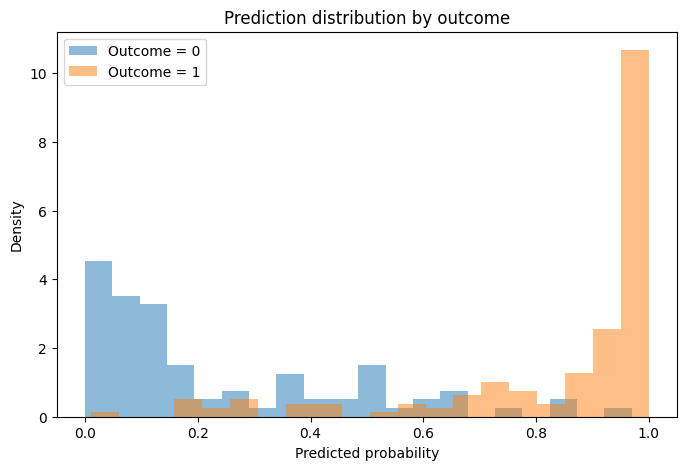

Brier score =  0.086
auc = 0.95 (CI: 0.92;0.98)


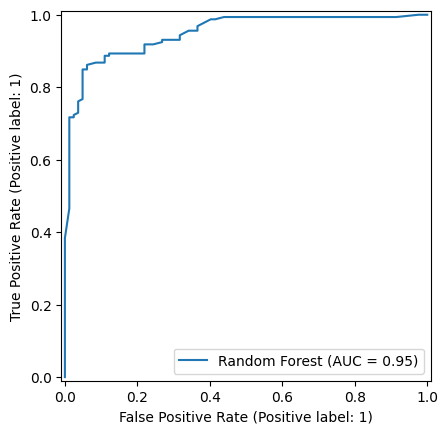

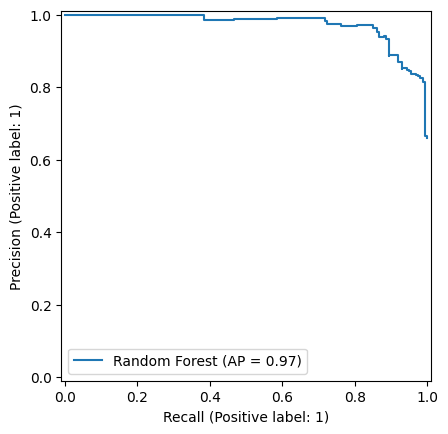

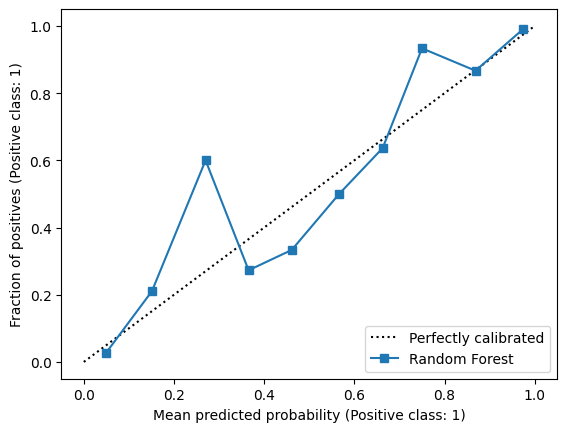

In [204]:
evaluate_model(
    y_true=df_prediction_test["outcome"],
    y_proba=df_prediction_test["prediction"]
)


## 6. Validation croisée

Le train/test split ne conserve que 20 % des patients pour l’évaluation. Lorsque le jeu de données est limité, cette stratégie peut conduire à une estimation instable des performances du modèle. En effet, le nombre de patients disponibles pour l’évaluation est réduit, mais également celui disponible pour l’entraînement du modèle. Cette approche est donc particulièrement critiquée dans le développement de modèles de prédiction clinique. Toutefois, elle reste pertinente lorsque le jeu de données est extrêmement volumineux et que les modèles développés sont très coûteux en ressources de calcul. En effet, les approches alternatives, telles que la validation croisée ou le bootstrap, nécessitent de ré-estimer le modèle un grand nombre de fois, ce qui peut être prohibitif en termes de temps de calcul.

Dans la suite du TD, nous allons introduire la validation croisée, et plus particulièrement la validation croisée à 10 folds. Dans cette approche, le jeu de données est divisé en 10 sous-échantillons, appelés folds. Le modèle est entraîné sur les patients présents dans 9 folds, puis évalué sur les patients du dixième fold, utilisé comme jeu de test. Le processus est ensuite répété en changeant le fold utilisé pour l'évaluation, jusqu'à ce que chacun des 10 folds ait été utilisé une fois comme jeu de test. Chaque observation est utilisée une fois comme donnée de validation, alors que le modèle qui produit sa prédiction a été entraîné sur les autres observations. Ainsi, chaque patient est évalué par un modèle qui n'a pas été entraîné sur ses données, ce qui permet de limiter le risque de surapprentissage lors de l'évaluation. Contrairement à une séparation simple entre un jeu d'entraînement et un jeu de test, la validation croisée permet ainsi d'utiliser l'ensemble des patients pour estimer les performances du modèle et fournit généralement une estimation plus robuste et moins dépendante d'une séparation particulière des données.

> ❓ Réalisez les étapes suivantes :
> 
> 1. Créez un objet `cv` de validation croisée stratifiée avec la fonction `StratifiedKFold`.
> 2. Utilisez la fonction `cross_val_predict` pour obtenir les prédictions en validation croisée (`cv`) du `pipeline`.
> 3. Construisez le dataframe `df_prediction_cv` contenant l'outcome `y` et les prédictions en validation croisée `oof_predictions`.
> 3. Utilisez la fonction `evaluate_model` pour évaluer les performances du modèle.

In [205]:
### A compléter
# 
# from sklearn.model_selection import StratifiedKFold, cross_val_predict
# 
# cv = StratifiedKFold(...)
# 
# oof_predictions = cross_val_predict(...)[:, 1]
# 
# df_prediction_cv = pd.DataFrame(data={...})

## 7. Optimisation des hyperparamètres : Train / Validation / Test

Certaines méthodes de machine learning nécessitent de choisir des **hyperparamètres**, c’est-à-dire des paramètres définis avant l’entraînement et qui contrôlent la manière dont le modèle est construit. Pour une forêt aléatoire, nous allons optimiser :

* `max_features` : proportion de variables considérées lors de chaque split, entre 0,1 et 1 ;
* `max_depth` : profondeur maximale des arbres, entre 2 et 15.

Nous fixons `n_estimators = 100` et testerons **100 configurations** d'hyperparamètres différentes. Le critère d’optimisation sera l’**AUC**.

Pour réaliser cette optimisation, les données sont séparées en trois ensembles :

* **train + validation** : utilisé pour rechercher les meilleurs hyperparamètres en validation croisée puis entraîner le modèle final ;
* **test** : conservé pour l’évaluation finale.

Le **jeu de test doit rester totalement indépendant** : il ne doit pas être utilisé pour choisir les hyperparamètres. Dans le cas contraire, les hyperparamètres risqueraient d'être adaptés aux données de test, ce qui conduirait à une estimation trop optimiste des performances du modèle.

Une fois les hyperparamètres sélectionnés, le modèle final peut être **réentraîné sur train + validation**, puis évalué une seule fois sur le jeu de test. L'AUC obtenue sur ce dernier constitue alors une estimation indépendante des performances du modèle sur de nouveaux patients.

**À retenir :** train pour **apprendre**, validation pour **choisir**, test pour **évaluer**.

La première étape consiste à spécifier les plages de recherche d'hyperparamètres.

> ❓ Créez un objet `param_distributions`, spécifiant les distributions d'échantillonnages des hyperparamètres.

In [ ]:
### A compléter
# from scipy.stats import randint, uniform
# 
# param_distributions = {
#     "classifier__max_depth": ...,
#     "classifier__max_features": ...,
# }

### 7.1 Algorithme de recherche d'hyperparamètres

Il existe de nombreux algorithmes permettant de rechercher les meilleurs hyperparamètres. Certains sont relativement simples, comme la **recherche par grille** (*Grid Search*) ou la **recherche aléatoire** (*Random Search*), tandis que d'autres sont plus élaborés, comme les algorithmes évolutionnaires, **CMA-ES**, **TPE** ou **PSO**.

Dans ce TD, nous utiliserons **Random Search**, qui est simple à mettre en œuvre et qui peut être plus efficace que Grid Search lorsque le nombre d'évaluations est limité. Les méthodes plus avancées dépassent le cadre de ce TD, mais peuvent être particulièrement intéressantes lorsque chaque évaluation du modèle est coûteuse.

**Notre exemple**

Nous souhaitons optimiser deux hyperparamètres :

* `max_features`, dont nous considérons ici une plage de valeurs comprise entre 0,1 et 1 ;
* `max_depth`, compris entre 2 et 15.

#### 7.1.1 Grid Search

Avec Grid Search, l'utilisateur définit à l'avance un ensemble de valeurs à tester pour chaque hyperparamètre. Par exemple :

* `max_features` : [0.1, 0.25, 0.5, 0.75, 1]
* `max_depth` : [2, 5, 8, 11, 15]

L'algorithme teste alors **toutes les combinaisons possibles**. Dans notre exemple, cela représente :

**5 × 5 = 25 évaluations.**

Cette approche devient rapidement coûteuse lorsque le nombre d'hyperparamètres augmente. Si nous ajoutons deux hyperparamètres supplémentaires, chacun avec 5 valeurs possibles, le nombre d'évaluations devient :

**5 × 5 × 5 × 5 = 625 évaluations.**

Grid Search présente donc deux principales limites. D'une part, il faut choisir à l'avance des valeurs pertinentes à tester, ce qui peut être difficile. D'autre part, le nombre de combinaisons augmente très rapidement avec le nombre d'hyperparamètres.

#### 7.1.2 Random Search

Avec Random Search, plutôt que de tester systématiquement toutes les combinaisons, l'algorithme **tire aléatoirement** une valeur pour chaque hyperparamètre à chaque nouvel essai. L'utilisateur définit principalement les distributions ou les bornes dans lesquelles ces valeurs peuvent être tirées.

Dans notre exemple, un essai pourrait par exemple utiliser `max_features = 0.37` et `max_depth = 7`, puis l'essai suivant une autre combinaison tirée aléatoirement.

L'avantage est que l'on peut fixer directement un **nombre d'évaluations** (par exemple 100), indépendamment du nombre d'hyperparamètres et du nombre de valeurs possibles. Random Search permet ainsi d'explorer plus facilement des espaces d'hyperparamètres de grande dimension avec un budget de calcul fixé.

Il faut toutefois garder à l'esprit que le caractère aléatoire de la méthode implique qu'une même exécution peut conduire à des configurations différentes. En pratique, on fixe donc une **graine aléatoire (*random seed*)** afin de rendre les résultats reproductibles.

> ❓ Créez une boucle for pour évaluer 100 essais d'un algorithme random search de recherche d'hyperparamètres (`max_features` et `max_depth`). Sotckez les résultats dans un dataframe `df_hp_optimisation` contenant le numéro d'essai, les valeurs d'hyperparamètres et l'auc (la métrique d'optimisation). Vous ferez ensuite une représentation graphique et déterminerez quelles valeurs vous semblent les plus prometteuses.

In [ ]:
### A compléter
nb_trial = 100
n_estimators = 100
max_features = [0.1, 1]
max_depth = [2, 15]

df_hp_optimisation = list()

# for trial_i in tqdm(np.arange(nb_trial)):
#     max_features_i = rand.uniform(...)
#     max_depth_i = rand.randint(...)
# 
#     rf_hp_trial = RandomForestClassifier(...)
#     rf_hp_trial.fit(...)
#     prediction_validation_trial = rf_hp_trial.predict_proba(...)[:, 1]
#     auc_i = roc_auc_score(...)[0]
#     df_hp_optimisation_i = pd.DataFrame({
#         "trial": [trial_i],
#         "max_features": [max_features_i],
#         "max_depth": [max_depth_i],
#         "auc": [auc_i],
#     })
#     df_hp_optimisation.append(df_hp_optimisation_i)
# 
# # Concatenate everything only once
# df_prediction_cv = pd.concat(df_prediction_cv_list, ignore_index=True)


> ❓ A partir des valeurs d'hyperparamètres choisies, entraîner votre modèle final sur le jeu d'entraînement + validation pour prédire sur le jeu test. Evaluez ce modèle.

In [ ]:
### A compléter
# rf_hp_set = RandomForestClassifier(...)
# rf_hp_set.fit(...)
# prediction_test_hp_set = rf_hp_set.predict_proba(...)[:, 1]
# df_prediction_test_hp_set = pd.DataFrame(...)
# evaluate_model(...)

## 8. Validation croisée nichée pour l’optimisation des hyperparamètres

Comme précédemment, la séparation des données en ensembles **train / validation / test** présente l'inconvénient de réduire la quantité de données disponible à chaque étape. Ce problème est particulièrement important lorsque le jeu de données est de petite taille : une partie des patients est utilisée pour choisir les hyperparamètres et une autre est conservée pour l'évaluation finale du modèle.

Une solution consiste à utiliser la **validation croisée nichée** (*nested cross-validation*). Cette approche repose sur deux boucles de validation croisée imbriquées :

1. La **boucle externe** permet d'estimer les performances du modèle sur des données qui n'ont pas été utilisées lors de l'optimisation des hyperparamètres.
2. La **boucle interne** permet de rechercher les meilleurs hyperparamètres en utilisant uniquement les données disponibles pour l'entraînement du fold externe.

Ainsi, chaque patient peut être utilisé pour l'entraînement ou la sélection des hyperparamètres, tout en étant évalué sur des données qui n'ont jamais été utilisées pour choisir le modèle.

### Exemple avec 10 folds

Supposons que l'on utilise une validation croisée à **10 folds** pour évaluer les performances du modèle. À chaque itération de la boucle externe, un fold est conservé comme **jeu de test** et les 9 autres folds sont utilisés pour l'optimisation des hyperparamètres.

La boucle interne réalise alors une validation croisée sur ces 9 folds. Pour chaque configuration d'hyperparamètres, le modèle est entraîné sur 8 folds et évalué sur le neuvième. Cette procédure est répétée afin que chacun des 9 folds serve une fois de validation.

L'algorithme peut être résumé ainsi :

```text
FOR fold_i IN [0, ..., 9]:

    # Boucle externe
    KEEP fold_i AS test_set_i

    FOR trial_i IN [0, ..., 99]:

        # Tirage d'une configuration d'hyperparamètres
        SAMPLE hyperparameters

        # Boucle interne
        FOR fold_j IN [0, ..., 9] AND fold_j != fold_i:

            TRAIN model on the 8 remaining folds
            EVALUATE model on fold_j

        CALCULATE mean validation performance
        STORE hyperparameters and performance

    SELECT best hyperparameters

    TRAIN final model on the 9 folds
    EVALUATE final model on fold_i
```

La boucle externe fournit ainsi **10 estimations indépendantes des performances**, une pour chaque fold utilisé comme jeu de test. Ces prédictions peuvent ensuite être regroupées afin d'obtenir une estimation globale des performances du modèle.

Cette méthode permet donc de réaliser simultanément **l'optimisation des hyperparamètres et l'évaluation du modèle**, sans utiliser les données de test pour choisir les hyperparamètres. Elle permet également d'utiliser une plus grande proportion des données pour l'entraînement qu'une séparation fixe train / validation / test.

**Attention toutefois : cette procédure peut être coûteuse en temps de calcul.** Dans notre exemple, 10 folds externes × 100 configurations d'hyperparamètres × 9 entraînements internes représentent déjà **9 000 entraînements de modèles**, auxquels s'ajoutent les 10 entraînements finaux. Le nombre d'entraînements augmente rapidement lorsque le nombre de folds ou de configurations testées augmente.

Dans le code ci-dessous, nous allons mettre en place cette **validation croisée nichée** pour optimiser les hyperparamètres de la forêt aléatoire. Les prédictions obtenues sur les folds externes seront ensuite regroupées afin d'évaluer les performances finales du modèle.


In [ ]:
# Evaluation du modèle
evaluate_model(
    y_true=df_prediction_niched["outcome"],
    y_proba=df_prediction_niched["prediction"]
)


## 9. Synthèse

Ce qui est important :

1. Questionner la question de recherche, ne pas nourrir le cimetière de modèle de prédiction.
2. Evaluer la faisabilité par un calcul de taille d'étude.
3. Bien faire attention au risque de surapprentissage (a minima split simple, si possible validation croisée ou bootstrap)
4. Correctement évaluer son modèle (ne pas oublier la calibration +++)
5. Penser au choix des hyperparamètres (par exemple avec l'algorithme random search)